# Diabetes prediction — reproducible analysis

AI-assisted technical notebook. Write the submitted report yourself under the rubric's authorship rule. This notebook inspects the completed experiment; training is a separate explicit command and is not silently rerun.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'src/diabetes').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src/diabetes').exists(), 'Open from project root or notebooks/'
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import joblib
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)
from diabetes.data import load_data, FEATURES, ZERO_MISSING, sha256
from diabetes.predict import predict, what_if
from IPython.display import display, Image
df = load_data()
results = json.loads((ROOT / 'reports/results.json').read_text())
assert sha256(ROOT / 'data/pima_raw.csv') == results['dataset_sha256']
print('Dataset shape:', df.shape)
print('Population: historical Pima women aged 21 and above; Outcome classification only.')

Dataset shape: (768, 9)
Population: historical Pima women aged 21 and above; Outcome classification only.


## Data understanding and partitions

The raw file is unchanged. Exploratory plots and preprocessing fitting use only training rows.

In [2]:
display(df.head())
print('Class counts:', df.Outcome.value_counts().to_dict())
splits = json.loads((ROOT / 'artifacts/splits.json').read_text())
assert not (set(splits['train']) & set(splits['test']))
assert not (set(splits['validation']) & set(splits['test']))
print('Split sizes:', results['split_sizes'])
display(pd.read_csv(ROOT / 'reports/data_quality.csv'))

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Class counts: {0: 500, 1: 268}
Split sizes: {'train': 460, 'validation': 154, 'test': 154}


,feature,missing_or_zero,missing_pct,zero_sentinel_count,iqr_outliers,minimum,maximum,median
0,Pregnancies,0,0.000000,0,1,0.000,14.000,3.000
1,Glucose,4,0.869565,4,0,56.000,197.000,117.000
2,BloodPressure,18,3.913043,18,12,24.000,114.000,72.000
3,SkinThickness,131,28.478261,131,2,7.000,99.000,30.000
4,Insulin,215,46.739130,215,12,16.000,744.000,125.000
5,BMI,6,1.304348,6,6,18.200,67.100,32.400
6,DiabetesPedigreeFunction,0,0.000000,0,16,0.084,2.329,0.389
7,Age,0,0.000000,0,11,21.000,81.000,29.000


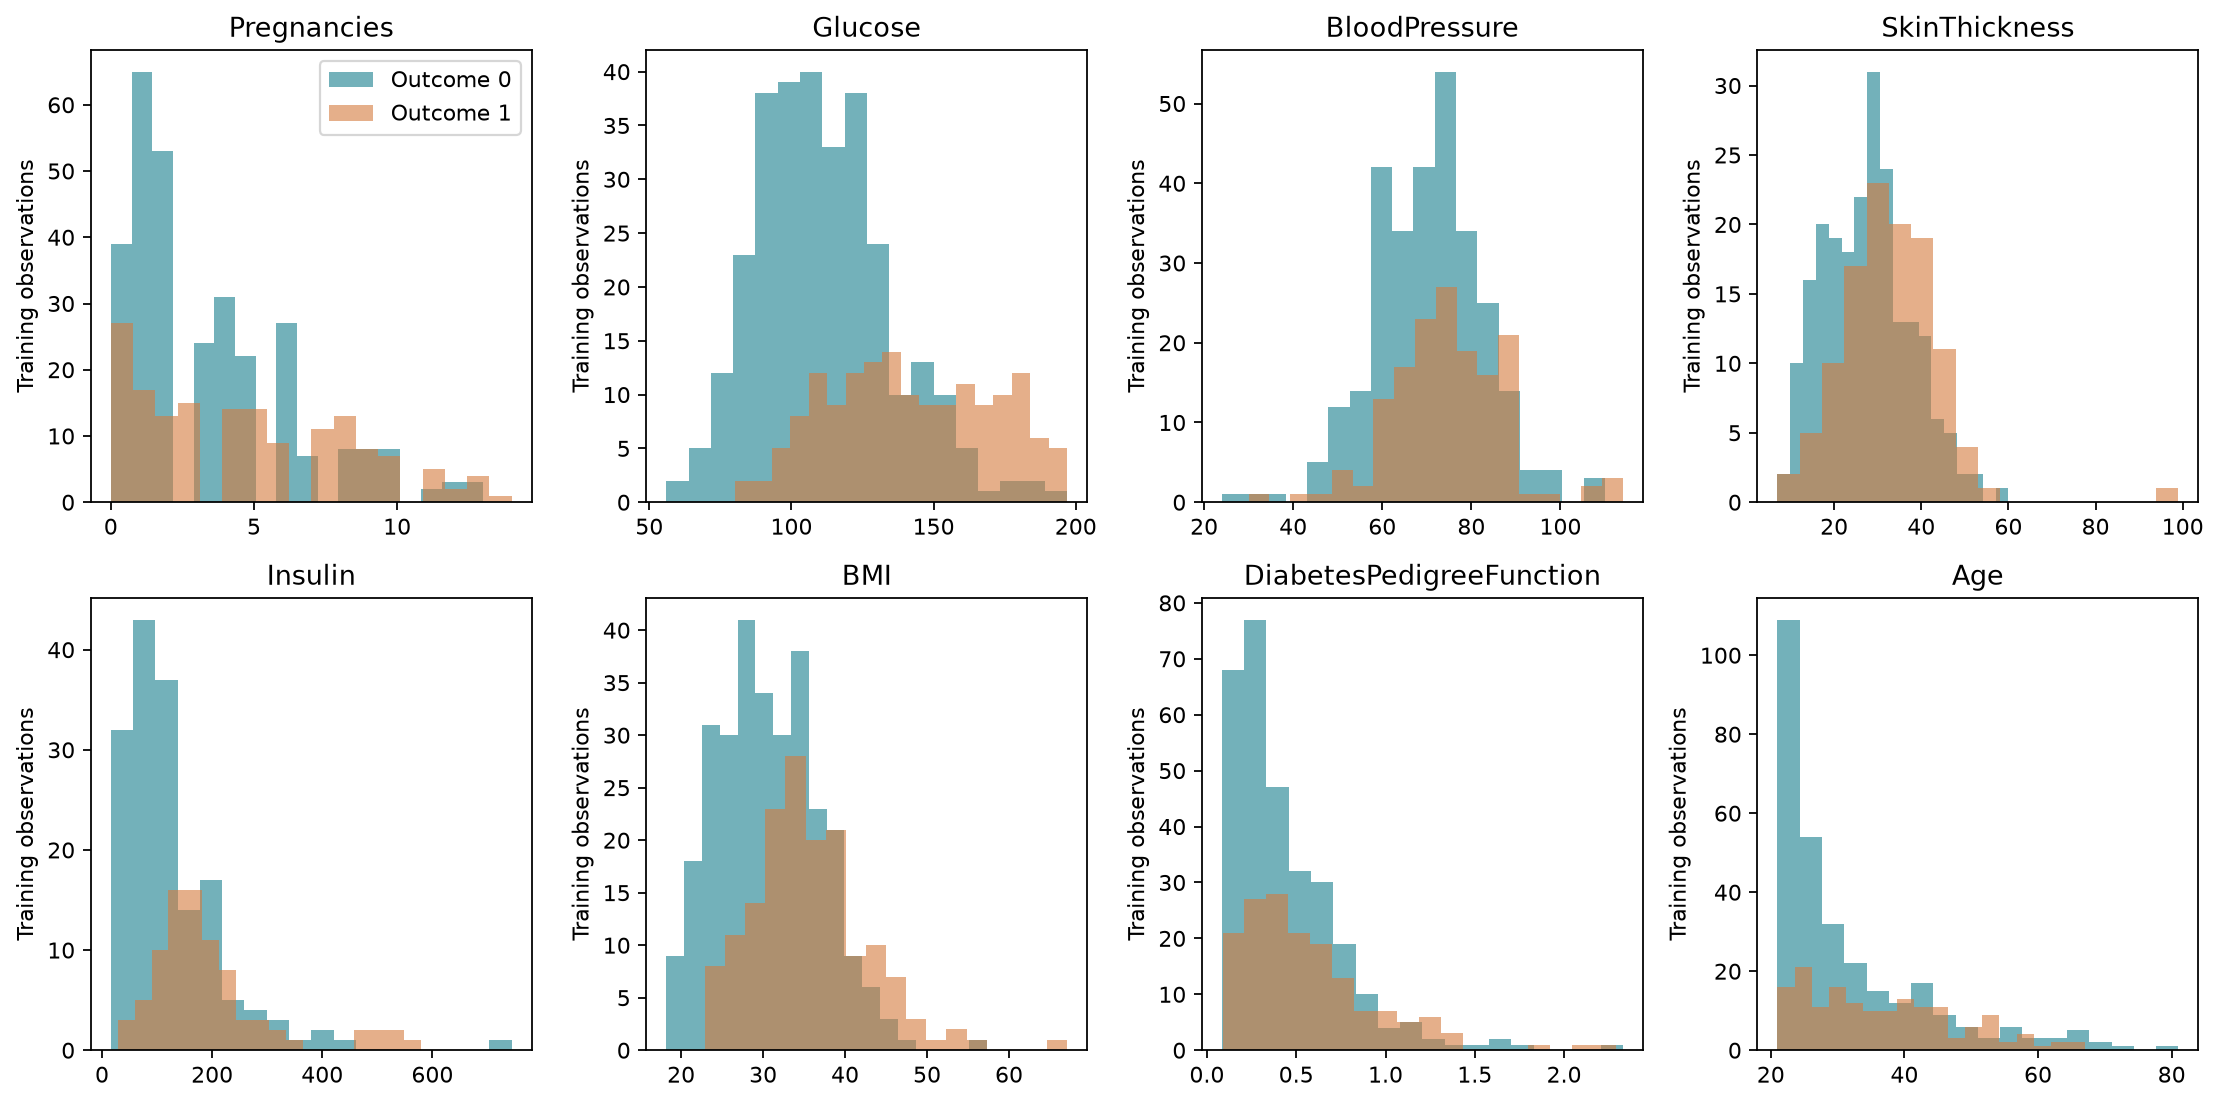

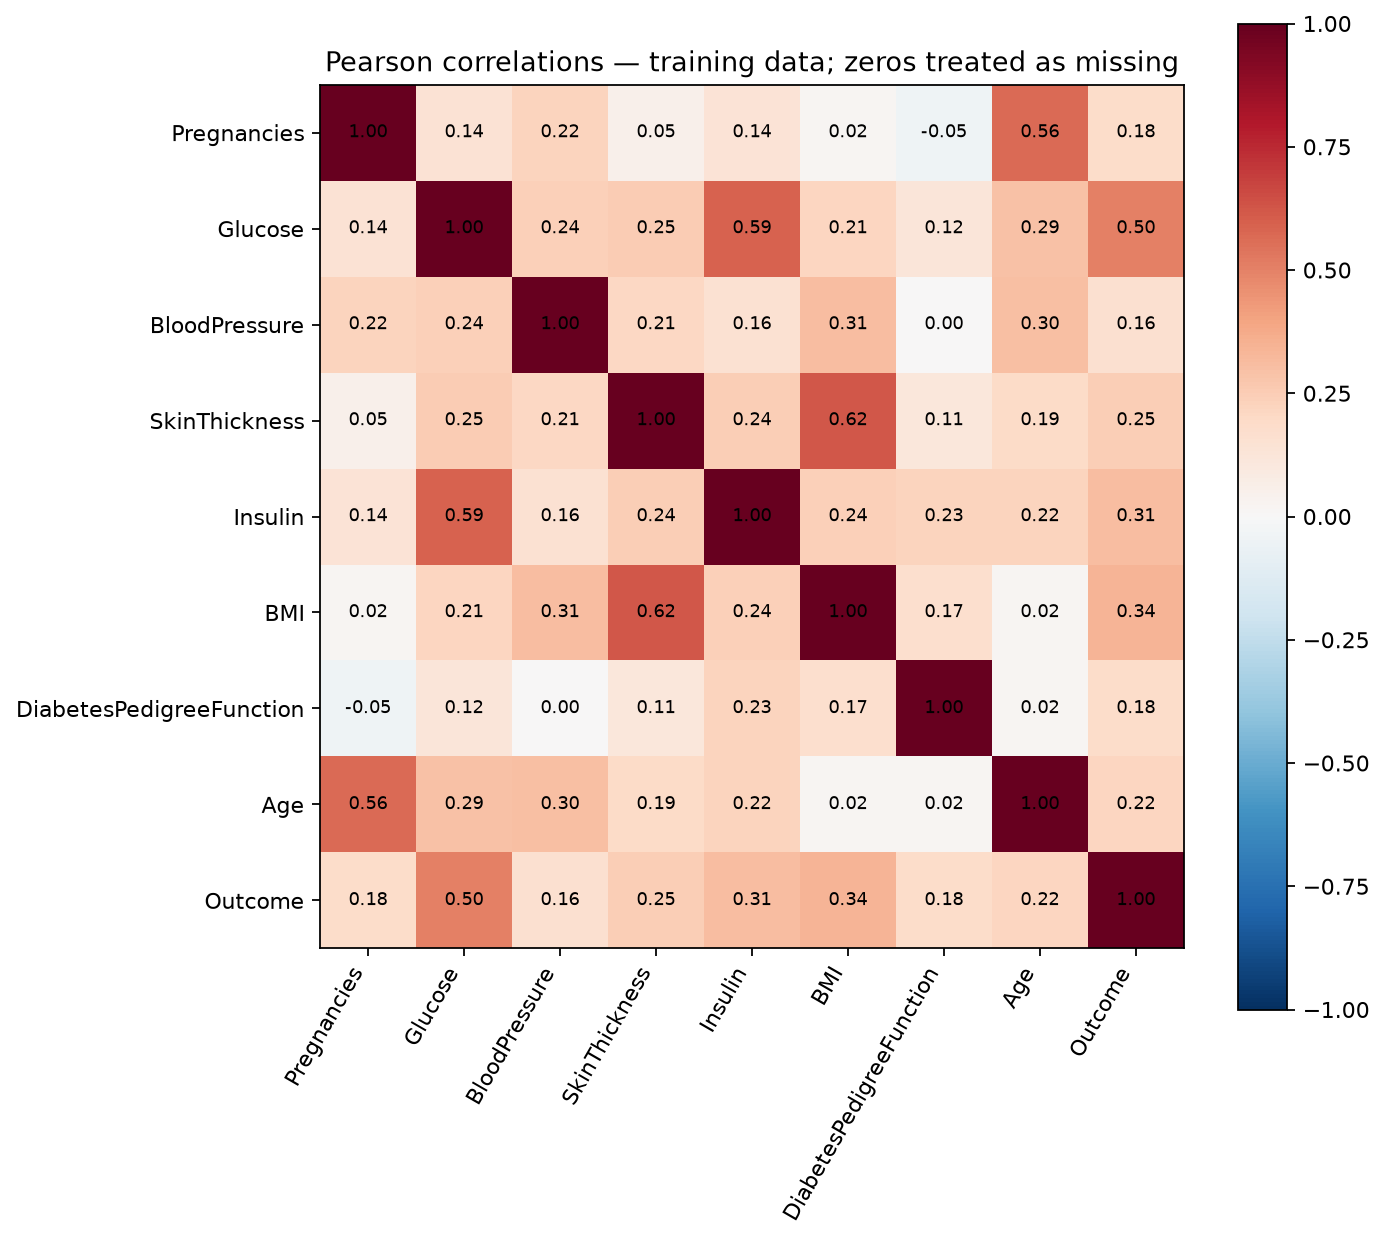

In [3]:
display(Image(filename=str(ROOT / 'reports/figures/feature_distributions.png')))
display(Image(filename=str(ROOT / 'reports/figures/correlation.png')))

## Feature engineering and selection

Compare original inputs, exploratory log/interaction features and fold-local ANOVA selection using fixed CV folds. Selection did not improve every learner. A CV-selected representation is not a clinical biomarker.

In [4]:
display(pd.read_csv(ROOT / 'reports/feature_ablation.csv'))
print('Selected representation:', results['selected_representation'])
display(pd.DataFrame(results['tuning']).T)

,learner,representation,mean_cv_auc,std_cv_auc,mean_cv_f1,mean_cv_brier
0,LogisticRegression,original,0.826250,0.020910,0.647431,0.157319
1,LogisticRegression,engineered,0.825417,0.019442,0.640733,0.157352
2,LogisticRegression,selected_5,0.820521,0.017847,0.623378,0.162248
3,ANN,original,0.794583,0.027246,0.587613,0.174241
4,ANN,engineered,0.755833,0.115388,0.569992,0.181753
5,ANN,selected_5,0.808229,0.037127,0.581009,0.169303


Selected representation: selected_5


,best_params,best_cv_auc,cv_auc_std,cv_train_auc
LogisticRegression,"{'model__class_weight': 'balanced', 'model__C'...",0.820625,0.015696,0.839935
RandomForest,"{'model__min_samples_leaf': 10, 'model__max_fe...",0.815104,0.024269,0.901439
GradientBoosting,"{'model__max_leaf_nodes': 7, 'model__max_iter'...",0.81375,0.018804,0.919766
SVM,"{'model__gamma': 0.03, 'model__class_weight': ...",0.818542,0.024109,0.858822
ANN,"{'model__learning_rate_init': 0.003, 'model__h...",0.821354,0.022648,0.843496


## Independent test evaluation

The first table uses 0.50 for all models; the second uses separately frozen validation thresholds. Average precision is the PR-AUC convention. The ensemble is a prespecified framework and is not guaranteed to win.

,model,accuracy,precision,recall,f1,specificity,roc_auc,pr_auc,brier,log_loss,ece_10_bins,tn,fp,fn,tp,threshold
0,LogisticRegression,0.694805,0.557377,0.629630,0.591304,0.73,0.782593,0.613365,0.190542,0.567495,0.119607,73.0,27.0,20.0,34.0,0.5
1,RandomForest,0.740260,0.600000,0.777778,0.677419,0.72,0.821481,0.678239,0.171971,0.511337,0.091431,72.0,28.0,12.0,42.0,0.5
2,GradientBoosting,0.740260,0.634615,0.611111,0.622642,0.81,0.822222,0.677188,0.164001,0.488575,0.064061,81.0,19.0,21.0,33.0,0.5
3,SVM,0.707792,0.604651,0.481481,0.536082,0.83,0.800370,0.665885,0.177343,0.523180,0.101388,83.0,17.0,28.0,26.0,0.5
4,ANN,0.727273,0.625000,0.555556,0.588235,0.82,0.795556,0.655140,0.179895,0.526412,0.085313,82.0,18.0,24.0,30.0,0.5
5,DummyPrior,0.649351,0.000000,0.000000,0.000000,1.00,0.500000,0.350649,0.227702,0.647865,0.002823,100.0,0.0,54.0,0.0,0.5
6,RawEnsemble,0.727273,0.607143,0.629630,0.618182,0.78,0.810741,0.671009,0.170872,0.507591,0.124543,78.0,22.0,20.0,34.0,0.5
7,CalibratedEnsemble,0.727273,0.625000,0.555556,0.588235,0.82,0.810741,0.671009,0.174615,0.516125,0.086326,82.0,18.0,24.0,30.0,0.5


,model,accuracy,precision,recall,f1,specificity,roc_auc,pr_auc,brier,log_loss,ece_10_bins,tn,fp,fn,tp,threshold
0,LogisticRegression,0.727273,0.615385,0.592593,0.603774,0.80,0.782593,0.613365,0.190542,0.567495,0.119607,80.0,20.0,22.0,32.0,0.60
1,RandomForest,0.740260,0.616667,0.685185,0.649123,0.77,0.821481,0.678239,0.171971,0.511337,0.091431,77.0,23.0,17.0,37.0,0.56
2,GradientBoosting,0.740260,0.592105,0.833333,0.692308,0.69,0.822222,0.677188,0.164001,0.488575,0.064061,69.0,31.0,9.0,45.0,0.28
3,SVM,0.714286,0.571429,0.740741,0.645161,0.70,0.800370,0.665885,0.177343,0.523180,0.101388,70.0,30.0,14.0,40.0,0.30
4,ANN,0.701299,0.566667,0.629630,0.596491,0.74,0.795556,0.655140,0.179895,0.526412,0.085313,74.0,26.0,20.0,34.0,0.39
5,DummyPrior,0.350649,0.350649,1.000000,0.519231,0.00,0.500000,0.350649,0.227702,0.647865,0.002823,0.0,100.0,0.0,54.0,0.34
6,RawEnsemble,0.707792,0.567164,0.703704,0.628099,0.71,0.810741,0.671009,0.170872,0.507591,0.124543,71.0,29.0,16.0,38.0,0.40
7,CalibratedEnsemble,0.714286,0.575758,0.703704,0.633333,0.72,0.810741,0.671009,0.174615,0.516125,0.086326,72.0,28.0,16.0,38.0,0.33


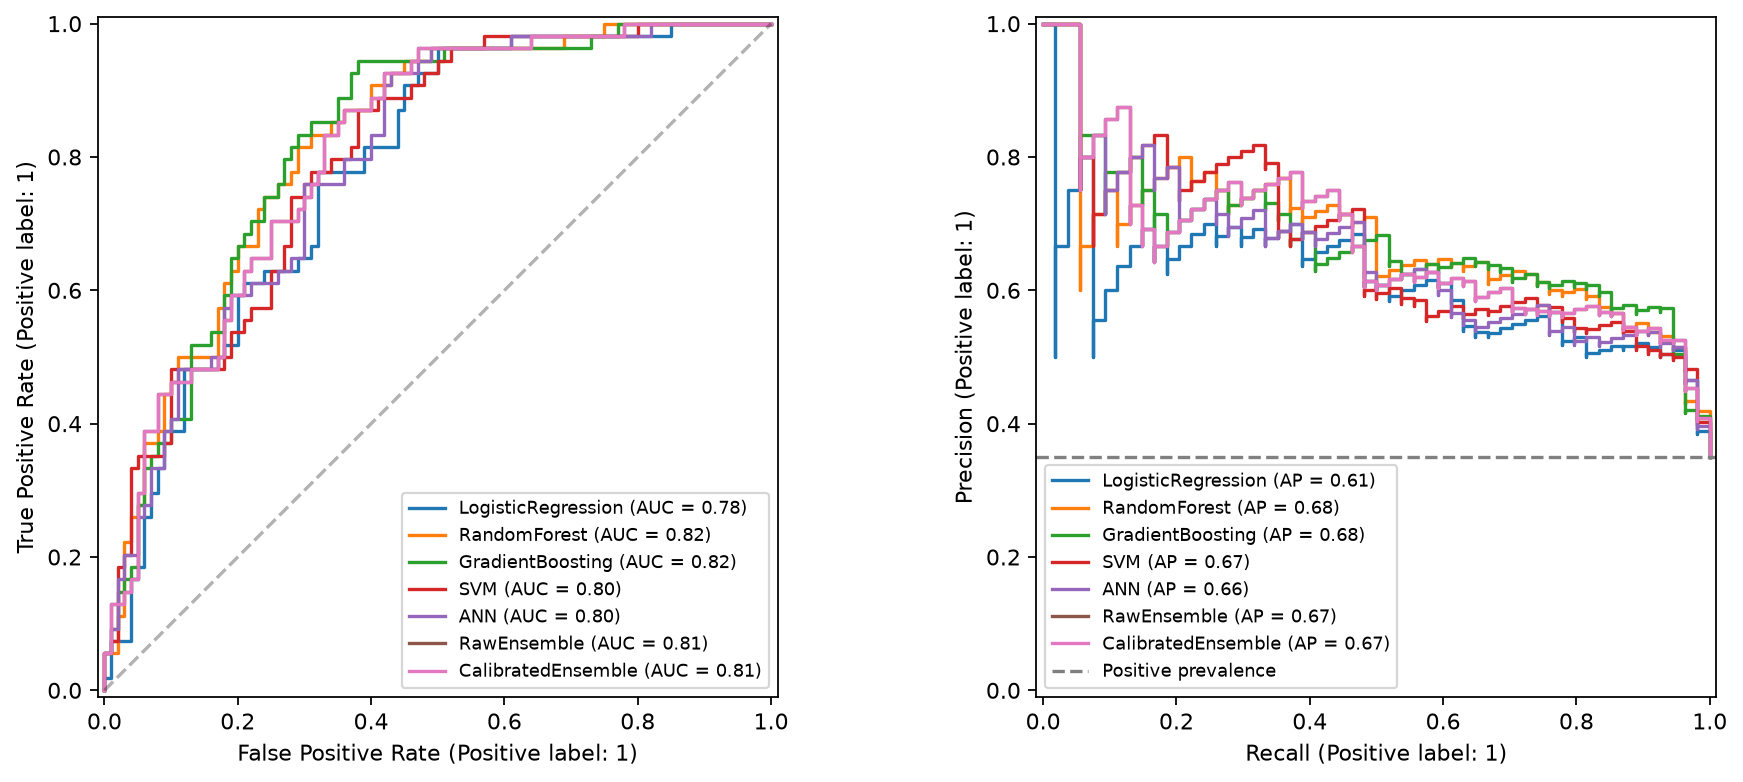

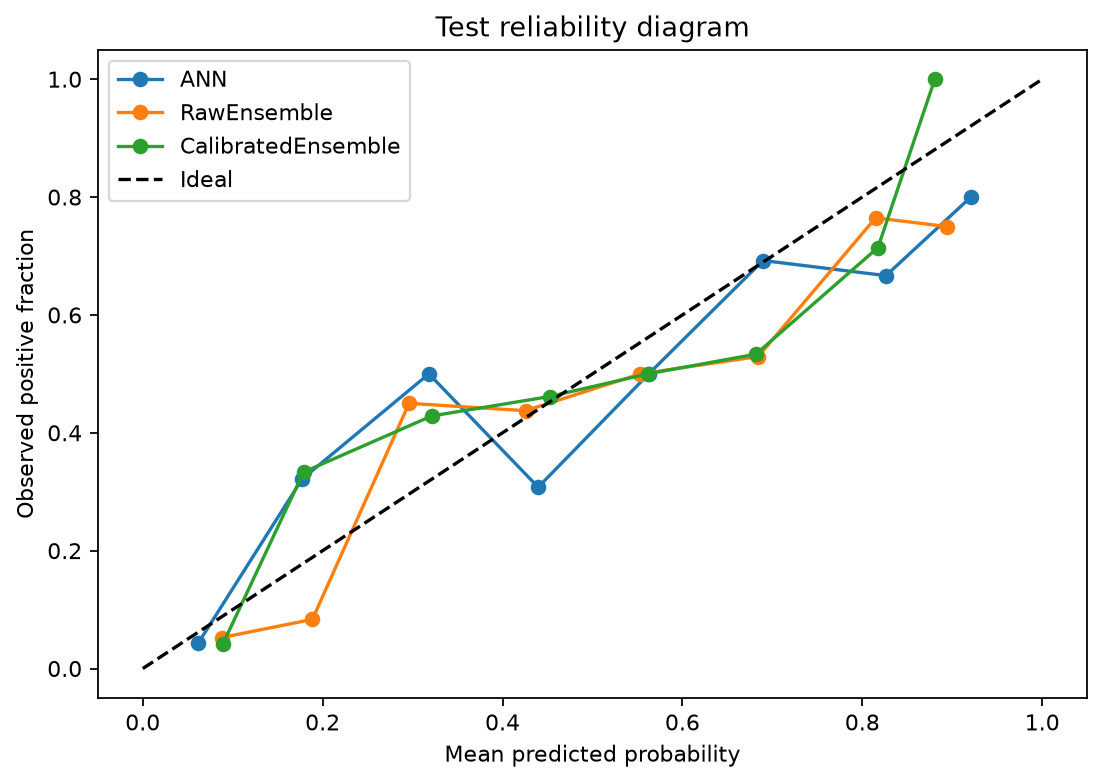

In [5]:
display(pd.read_csv(ROOT / 'reports/test_metrics_default.csv'))
display(pd.read_csv(ROOT / 'reports/test_metrics_validation_threshold.csv'))
display(Image(filename=str(ROOT / 'reports/figures/roc_pr_curves.png')))
display(Image(filename=str(ROOT / 'reports/figures/calibration.png')))

Conditional bootstrap intervals:
{
  "accuracy": [
    0.6428571428571429,
    0.7857142857142857
  ],
  "precision": [
    0.4931407583879293,
    0.6721382136800452
  ],
  "recall": [
    0.5740740740740741,
    0.8148148148148148
  ],
  "f1": [
    0.5426290894757587,
    0.7192982456140351
  ],
  "specificity": [
    0.63,
    0.81
  ],
  "roc_auc": [
    0.7360555555555556,
    0.8759305555555555
  ],
  "pr_auc": [
    0.5753726896423731,
    0.7876869261833276
  ],
  "brier": [
    0.14185186117338866,
    0.210351372812372
  ]
}
Prespecified comparison against ANN
{
  "mcnemar_exact_p": 1.0,
  "a_only_correct": 2,
  "b_only_correct": 2,
  "auc_difference_a_minus_b": 0.01518518518518519,
  "paired_auc_difference_95_ci": [
    0.0005555555555555314,
    0.03203703703703687
  ],
  "note": "Single prespecified comparison; not proof of equivalence or clinical superiority."
}


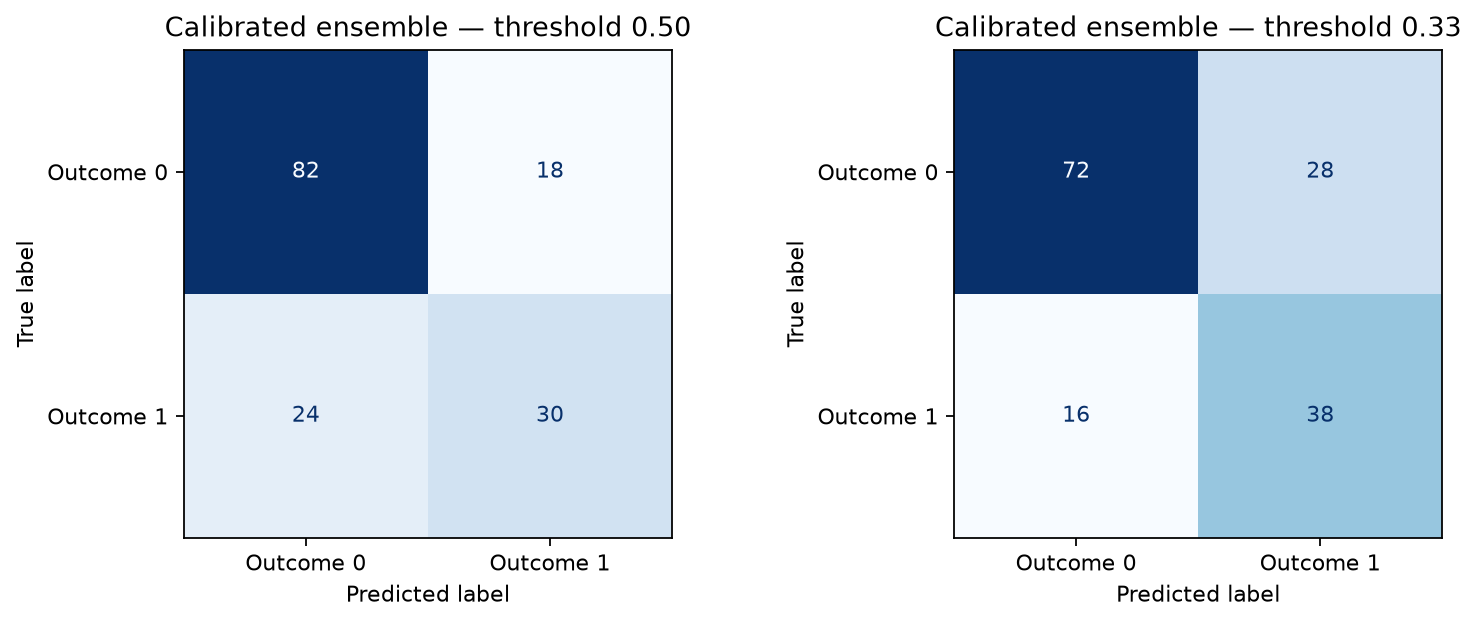

In [6]:
print('Conditional bootstrap intervals:')
print(json.dumps(results['ensemble_operating_95_ci'], indent=2))
print('Prespecified comparison against', results['best_cv_baseline'])
print(json.dumps(results['statistical_comparison'], indent=2))
display(Image(filename=str(ROOT / 'reports/figures/confusion_matrices.png')))

## Full-model local explanation and inference

Shapley values are exact for the finite 24-row background and all eight raw-feature coalitions. Background substitution is not a causal intervention. The summary plot covers only 12 fixed examples.

{
  "probability": 0.24874187801108438,
  "predicted_outcome": 0,
  "threshold": 0.33,
  "components": {
    "LogisticRegression": 0.3727150171282927,
    "RandomForest": 0.44313102717912567,
    "GradientBoosting": 0.3422228330649507,
    "SVM": 0.2875706088717159,
    "ANN": 0.21625145070133922
  },
  "component_std": 0.0767897212780289,
  "notes": [],
  "scope": "Educational classification of historical Pima Outcome labels; not a diagnosis or validated future risk forecast.",
  "explanation": {
    "baseline": 0.23144719994511154,
    "probability": 0.24874187801108438,
    "contributions": {
      "Pregnancies": 0.0,
      "Glucose": -0.003846694813016605,
      "BloodPressure": 0.0,
      "SkinThickness": 0.0024426200244795446,
      "Insulin": -0.02732330731664429,
      "BMI": 0.014789688886256893,
      "DiabetesPedigreeFunction": 0.0,
      "Age": 0.03123237128489725
    },
    "additivity_error": 5.551115123125783e-17,
    "background_size": 24,
    "method": "exact intervent

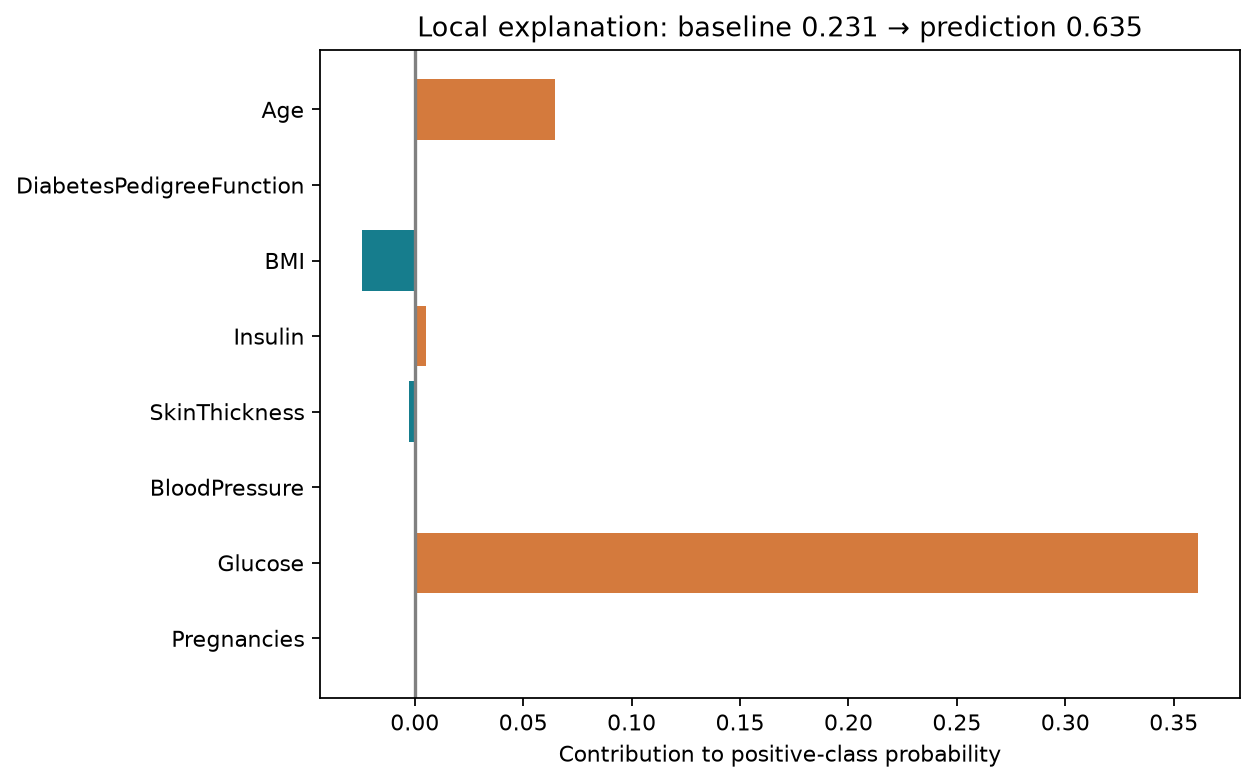

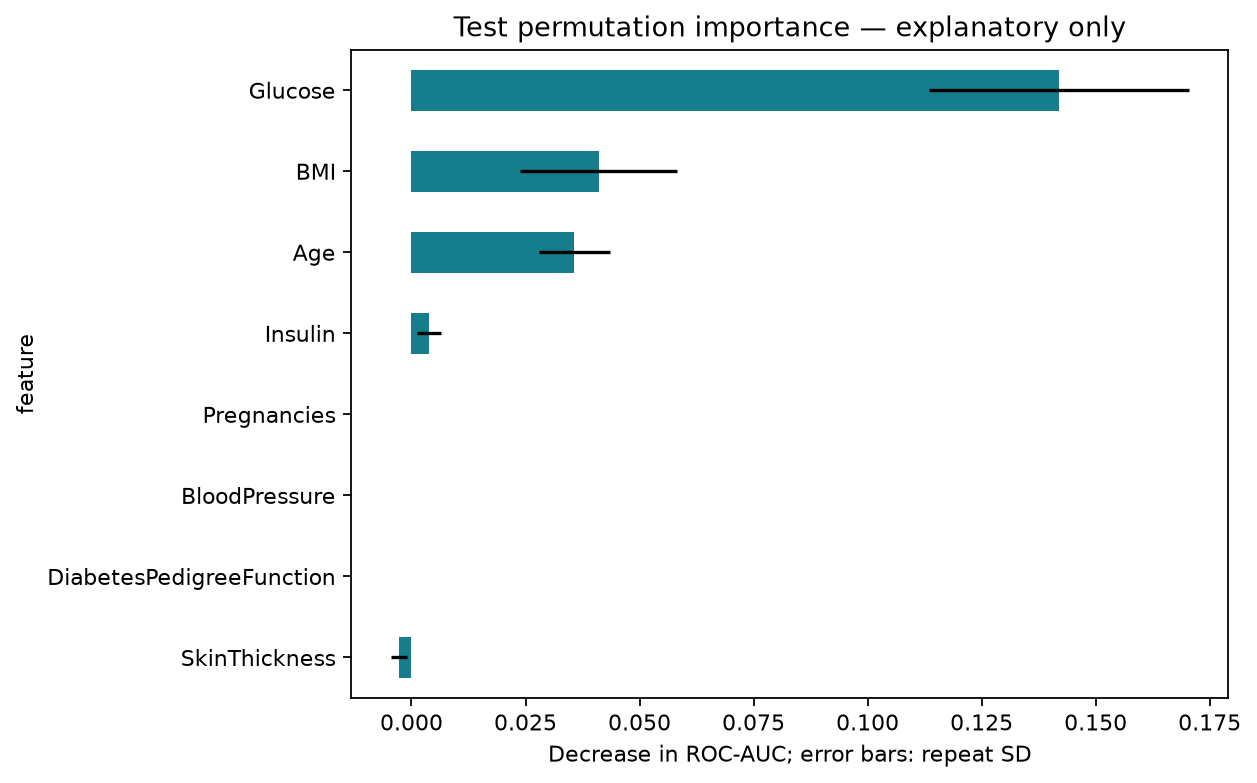

In [7]:
bundle = joblib.load(ROOT / 'artifacts/model.joblib')
inputs = dict(zip(FEATURES, [2,120,70,25,85,30,.45,32]))
prediction = predict(bundle, inputs)
print(json.dumps(prediction, indent=2))
assert prediction['explanation']['additivity_error'] < 1e-12
display(Image(filename=str(ROOT / 'reports/figures/local_shapley.png')))
display(Image(filename=str(ROOT / 'reports/figures/permutation_importance.png')))

## Uncertainty and what-if

Component SD is a disagreement heuristic, not a confidence interval. The scenario below explores the trained model and is not medical advice or an estimated treatment benefit.

{'feature': 'Glucose', 'value': 110, 'baseline_probability': 0.24874187801108438, 'scenario_probability': 0.21186529883694769, 'difference': -0.0368765791741367, 'notes': [], 'interpretation': 'An association within the model, not a treatment effect or medical recommendation.'}


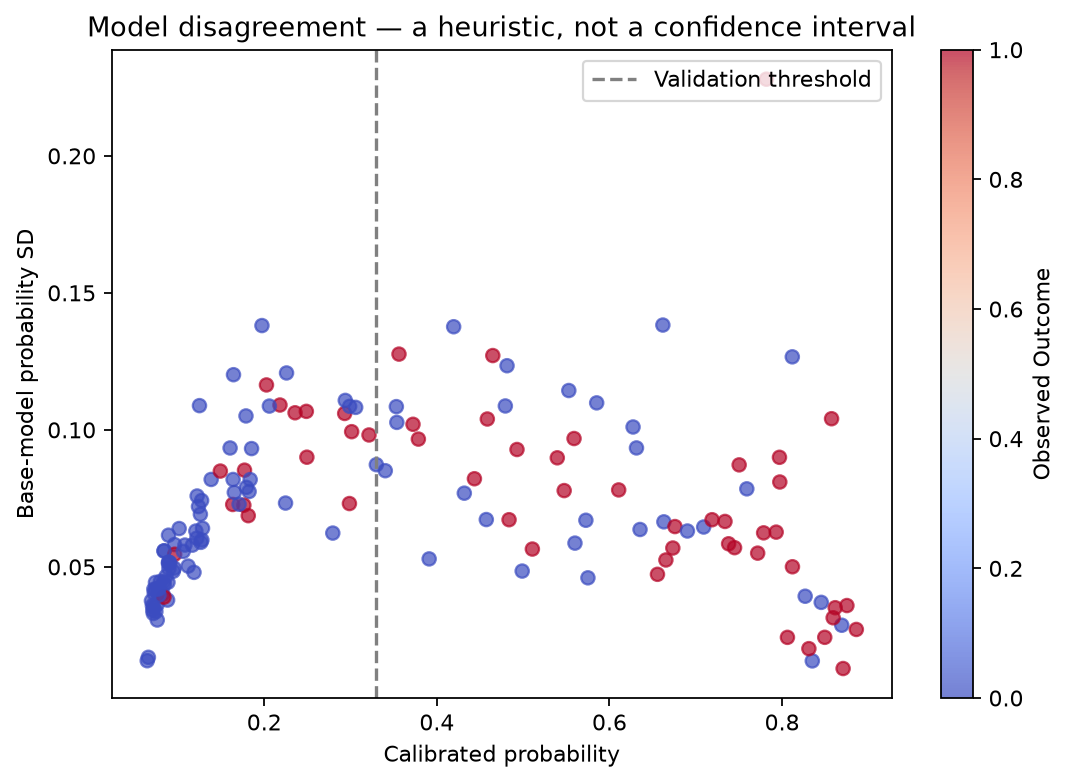

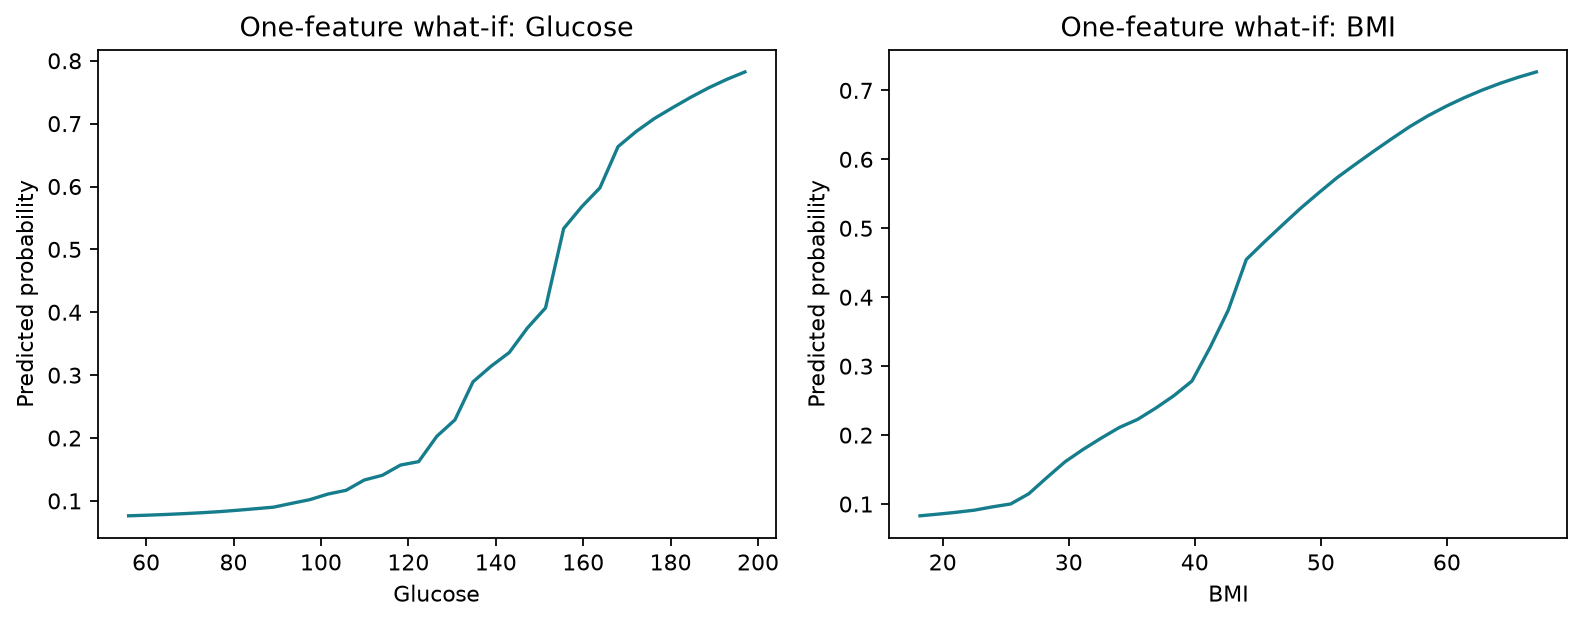

In [8]:
scenario = what_if(bundle, inputs, 'Glucose', 110)
print({key:value for key,value in scenario.items() if key != 'curve'})
display(Image(filename=str(ROOT / 'reports/figures/uncertainty.png')))
display(Image(filename=str(ROOT / 'reports/figures/what_if.png')))

## Reproduce and reflect

From the project root: `PYTHONPATH=src python -m diabetes.train`, then `PYTHONPATH=src python scripts/build_deliverables.py`. See the README for setup.

Write your own answers: Why did calibration worsen Brier? Why did the engineered ANN perform worse? What does the independent test establish? What additional external validation is necessary?